# 📓 Catatan Coretan Bimbingan 06: Analisis Distribusi Bobot ($w$)

Dokumen ini mendokumentasikan penjabaran teoretis, analisis komparasi matematis, dan simulasi numerik terkait perbedaan mendasar antara model dengan bobot acak ($w$ berdistribusi Gaussian) vs bobot deterministik ($w$ skalar konstan).

---

## ❓ Pertanyaan:
> **Apakah pembuktian untuk $w$ berdistribusi normal dengan $w$ yang tidak berdistribusi (skalar konstan / deterministik) berbeda?**

---

## 💡 Jawaban Singkat:
**YA, SANGAT BERBEDA SECARA FUNDAMENTAL**, baik dari segi:
1. **Status Matematis Fungsi Laten $f(x)$**:
   - Jika $w$ adalah skalar tetap (deterministik): $f(x) = wx$ **bukan peubah acak**, melainkan nilai pasti.
   - Jika $w \sim \mathcal{N}(0, \sigma_w^2)$: $f(x) = wx$ **adalah peubah acak Gaussian**.
2. **Sumber Keacakan pada $y$**:
   - $w$ deterministik: Satu-satunya sumber keacakan adalah derau pengukuran $\varepsilon \sim \mathcal{N}(0, \sigma_n^2)$.
   - $w$ berdistribusi: Keacakan berasal dari **dua peubah acak independen**, yaitu ketidakpastian model/bobot ($w$) dan derau pengukuran ($\varepsilon$).
3. **MGF dan Distribusi Hasil**:
   - $w$ deterministik: $y \sim \mathcal{N}(wx, \; \sigma_n^2)$ $\implies$ Variansi konstan/homoskedastik (tidak bergantung pada $x$).
   - $w$ berdistribusi: $y \sim \mathcal{N}(0, \; x^2 \sigma_w^2 + \sigma_n^2)$ $\implies$ Variansi bergantung pada masukan $x$ (heteroskedastik).
4. **Korelasi Antar-Titik (Jembatan ke Gaussian Process)**:
   - $w$ deterministik: Observasi pada $x_1$ dan $x_2$ independen, tidak memunculkan fungsi kovariansi/kernel.
   - $w$ berdistribusi: Observasi pada $x_1$ dan $x_2$ berkorelasi melalui $\operatorname{Cov}(f(x_1), f(x_2)) = x_1 x_2 \sigma_w^2$, yang melahirkan **fungsi kernel linier** $k(x_1, x_2)$!

---
## 📐 Penjabaran Matematis Lengkap: Kasus A vs Kasus B

### 1. Kasus A: $w$ Skalar Konstan / Deterministik (Frequentist)
Pada regresi linier klasik, bobot $w \in \mathbb{R}$ adalah parameter tetap yang tidak memiliki ketidakpastian distribusi.
* Model:
  $$y = wx + \varepsilon, \quad \text{dengan } \varepsilon \sim \mathcal{N}(0, \sigma_n^2)$$
* Status $f(x) = wx$: **Konstanta**, bukan variabel acak. MGF dari konstanta:
  $$M_{f(x)}(t) = \mathbb{E}\left[ e^{t (wx)} \right] = e^{t wx}$$
* MGF dari derau $\varepsilon \sim \mathcal{N}(0, \sigma_n^2)$:
  $$M_{\varepsilon}(t) = \mathbb{E}\left[ e^{t \varepsilon} \right] = \exp\left( \frac{1}{2} \sigma_n^2 t^2 \right)$$
* MGF dari observasi $y$:
  $$\begin{aligned}
  M_y(t) &= \mathbb{E}\left[ e^{t (wx + \varepsilon)} \right] = \mathbb{E}\left[ e^{t wx} \cdot e^{t \varepsilon} \right] \\
  &= e^{t wx} \cdot \mathbb{E}\left[ e^{t \varepsilon} \right] \quad (\text{karena } e^{t wx} \text{ adalah konstanta non-acak}) \\
  &= e^{t wx} \cdot \exp\left( \frac{1}{2} \sigma_n^2 t^2 \right) \\
  &= \exp\left( (wx) t + \frac{1}{2} \sigma_n^2 t^2 \right)
  \end{aligned}$$
* **Kesimpulan Kasus A (Teorema Keunikan MGF)**:
  Bentuk ini memiliki parameter $\mu_y = wx$ dan variansi $\sigma_y^2 = \sigma_n^2$. Maka:
  $$\mathbf{y \sim \mathcal{N}\left( wx, \; \sigma_n^2 \right)}$$
  > **Catatan Kunci**: Nilai input $x$ hanya menggeser rata-rata ($\mathbb{E}[y] = wx$), sedangkan variansinya **konstan** ($\operatorname{Var}(y) = \sigma_n^2$) di semua titik $x$.

---

### 2. Kasus B: $w$ Berdistribusi Normal (Bayesian / Weight-Space View)
Pada sudut pandang Bayesian, bobot $w$ diperlakukan sebagai peubah acak dengan distribusi prior Gaussian.
* Model:
  $$f(x) = wx, \quad y = f(x) + \varepsilon, \quad \text{dengan } w \sim \mathcal{N}(0, \sigma_w^2), \quad \varepsilon \sim \mathcal{N}(0, \sigma_n^2), \quad w \perp \varepsilon$$
* Status $f(x) = wx$: **Variabel acak Gaussian**. MGF dari $f(x)$:
  $$\begin{aligned}
  M_{f(x)}(t) &= \mathbb{E}_w\left[ e^{t (wx)} \right] = \mathbb{E}_w\left[ e^{(tx) w} \right] \\
  &= M_w(tx) \quad (\text{karena } w \sim \mathcal{N}(0, \sigma_w^2) \implies M_w(u) = \exp(\tfrac{1}{2} \sigma_w^2 u^2)) \\
  &= \exp\left( \frac{1}{2} \sigma_w^2 (tx)^2 \right) \\
  &= \exp\left( \frac{1}{2} t^2 \left( x^2 \sigma_w^2 \right) \right)
  \end{aligned}$$
  Berdasarkan Teorema Keunikan MGF:
  $$\mathbf{f(x) \sim \mathcal{N}\left( 0, \; x^2 \sigma_w^2 \right)}$$
* MGF dari observasi $y = f(x) + \varepsilon$:
  Karena $w$ dan $\varepsilon$ saling bebas ($w \perp \varepsilon$), maka $f(x)$ dan $\varepsilon$ juga saling bebas. MGF dari penjumlahan dua peubah acak independen adalah hasil kali MGF-nya:
  $$\begin{aligned}
  M_y(t) &= \mathbb{E}_{w, \varepsilon}\left[ e^{t (f(x) + \varepsilon)} \right] \\
  &= \mathbb{E}_w\left[ e^{t f(x)} \right] \cdot \mathbb{E}_\varepsilon\left[ e^{t \varepsilon} \right] \\
  &= M_{f(x)}(t) \cdot M_{\varepsilon}(t) \\
  &= \exp\left( \frac{1}{2} t^2 \left( x^2 \sigma_w^2 \right) \right) \cdot \exp\left( \frac{1}{2} \sigma_n^2 t^2 \right) \\
  &= \exp\left( \frac{1}{2} t^2 \left( x^2 \sigma_w^2 + \sigma_n^2 \right) \right)
  \end{aligned}$$
* **Kesimpulan Kasus B (Teorema Keunikan MGF)**:
  Bentuk ini memiliki parameter $\mu_y = 0$ dan variansi $\sigma_y^2 = x^2 \sigma_w^2 + \sigma_n^2$. Maka:
  $$\mathbf{y \sim \mathcal{N}\left( 0, \; x^2 \sigma_w^2 + \sigma_n^2 \right)}$$
  > **Catatan Kunci**: Variansi total terdiri dari **ketidakpastian epistemik** ($x^2 \sigma_w^2$) yang membesar seiring besarnya $|x|$, ditambah **ketidakpastian aleatorik** derau ($\sigma_n^2$).

---
## 📊 Tabel Perbandingan Komprehensif

| Karakteristik | Kasus A: $w$ Deterministik (Skalar Tetap) | Kasus B: $w$ Probabilistik ($w \sim \mathcal{N}(0, \sigma_w^2)$) |
| :--- | :--- | :--- |
| **Paradigma** | Frequentist / Classical Linear Regression | Bayesian Linear Regression / Weight-Space GP |
| **Sifat Parameter $w$** | Nilai konstan tetap (*fixed true value*) | Variabel acak dengan prior Gaussian |
| **Status $f(x) = wx$** | **Bukan peubah acak** (deterministik) | **Peubah acak Gaussian** |
| **MGF $M_{f(x)}(t)$** | $e^{t(wx)}$ (pergeseran eksponensial linier) | $\exp\left(\frac{1}{2} t^2 (x^2 \sigma_w^2)\right)$ (bentuk kuadratik Gaussian) |
| **Distribusi $f(x)$** | Dirac delta $\delta(f - wx)$ (degenerasi) | $\mathcal{N}(0, \; x^2 \sigma_w^2)$ |
| **Variansi Laten $\operatorname{Var}(f(x))$** | $0$ (pasti, tidak ada ketidakpastian fungsi) | $x^2 \sigma_w^2$ (bergantung jarak $x$ dari titik pusat) |
| **Sumber Keacakan $y$** | Hanya derau $\varepsilon$ | Dua sumber: Bobot $w$ dan Derau $\varepsilon$ |
| **Mekanisme MGF $M_y(t)$** | $e^{twx} \cdot M_\varepsilon(t)$ (faktor konstanta keluar dari ekspektasi) | $M_{f(x)}(t) \cdot M_\varepsilon(t)$ (perkalian MGF dua peubah acak independen) |
| **MGF Observasi $M_y(t)$** | $\exp\left((wx)t + \frac{1}{2}\sigma_n^2 t^2\right)$ | $\exp\left(\frac{1}{2} t^2 (x^2 \sigma_w^2 + \sigma_n^2)\right)$ |
| **Distribusi Observasi $y$** | $\mathcal{N}(wx, \; \sigma_n^2)$ | $\mathcal{N}(0, \; x^2 \sigma_w^2 + \sigma_n^2)$ |
| **Rata-rata $\mathbb{E}[y]$** | $wx$ (bergantung pada input $x$) | $0$ (jika prior mean nol $\mu_w = 0$) |
| **Variansi Total $\operatorname{Var}(y)$** | $\sigma_n^2$ (**konstan / homoskedastik**) | $x^2 \sigma_w^2 + \sigma_n^2$ (**heteroskedastik**) |
| **Jenis Ketidakpastian** | Hanya aleatorik (derau data) | Epistemik ($x^2 \sigma_w^2$) + Aleatorik ($\sigma_n^2$) |
| **Kovariansi Antar Titik** | $\operatorname{Cov}(f(x_1), f(x_2)) = 0$ | $\operatorname{Cov}(f(x_1), f(x_2)) = x_1 x_2 \sigma_w^2$ |
| **Kemunculan Kernel** | **Tidak ada fungsi kernel** | **Melahirkan Kernel Linier** $k(x_1, x_2) = x_1 x_2 \sigma_w^2$ |
| **Jembatan ke GP** | Tidak dapat ditransisikan ke GP | Fondasi transisi *Weight-Space* ke *Function-Space* |

In [1]:
import numpy as np
import pandas as pd

# =========================================================================
# SIMULASI MONTE CARLO: VERIFIKASI MGF EMPIRIS VS TEORITIS
# =========================================================================

# Parameter simulasi
np.random.seed(42)
N_samples = 500_000
x_val = 2.0        # Titik input yang diuji
sigma_n = 0.5      # Standar deviasi noise
w_fixed = 1.5      # Skalar deterministik untuk Kasus A
sigma_w = 1.0      # Standar deviasi bobot acak untuk Kasus B

# Nilai parameter uji MGF (t)
t_values = np.array([-0.3, -0.15, 0.0, 0.15, 0.3])

# 1. Sampel Kasus A: w deterministik
eps_A = np.random.normal(0, sigma_n, size=N_samples)
y_A = w_fixed * x_val + eps_A

# 2. Sampel Kasus B: w Gaussian acak
w_samples = np.random.normal(0, sigma_w, size=N_samples)
eps_B = np.random.normal(0, sigma_n, size=N_samples)
y_B = w_samples * x_val + eps_B

# Evaluasi MGF Empiris vs MGF Teoritis
results = []
for t in t_values:
    # Kasus A: w deterministik
    mgf_emp_A = np.mean(np.exp(t * y_A))
    mgf_theo_A = np.exp((w_fixed * x_val) * t + 0.5 * (sigma_n**2) * (t**2))
    
    # Kasus B: w Gaussian acak
    mgf_emp_B = np.mean(np.exp(t * y_B))
    var_B_theo = (x_val**2) * (sigma_w**2) + (sigma_n**2)
    mgf_theo_B = np.exp(0.5 * var_B_theo * (t**2))
    
    results.append({
        "t": t,
        "Kasus A (Empiris)": mgf_emp_A,
        "Kasus A (Teoritis)": mgf_theo_A,
        "Selisih A": abs(mgf_emp_A - mgf_theo_A),
        "Kasus B (Empiris)": mgf_emp_B,
        "Kasus B (Teoritis)": mgf_theo_B,
        "Selisih B": abs(mgf_emp_B - mgf_theo_B),
    })

df_results = pd.DataFrame(results)
print("--- HASIL VERIFIKASI MGF MONTE CARLO ---")
print(df_results.to_string(index=False))

--- HASIL VERIFIKASI MGF MONTE CARLO ---
    t  Kasus A (Empiris)  Kasus A (Teoritis)  Selisih A  Kasus B (Empiris)  Kasus B (Teoritis)  Selisih B
-0.30           0.411246            0.411169   0.000077           1.212186            1.210762   0.001423
-0.15           0.639482            0.639424   0.000058           1.049667            1.048974   0.000693
 0.00           1.000000            1.000000   0.000000           1.000000            1.000000   0.000000
 0.15           1.572596            1.572729   0.000134           1.048183            1.048974   0.000791
 0.30           2.487017            2.487430   0.000413           1.208817            1.210762   0.001945


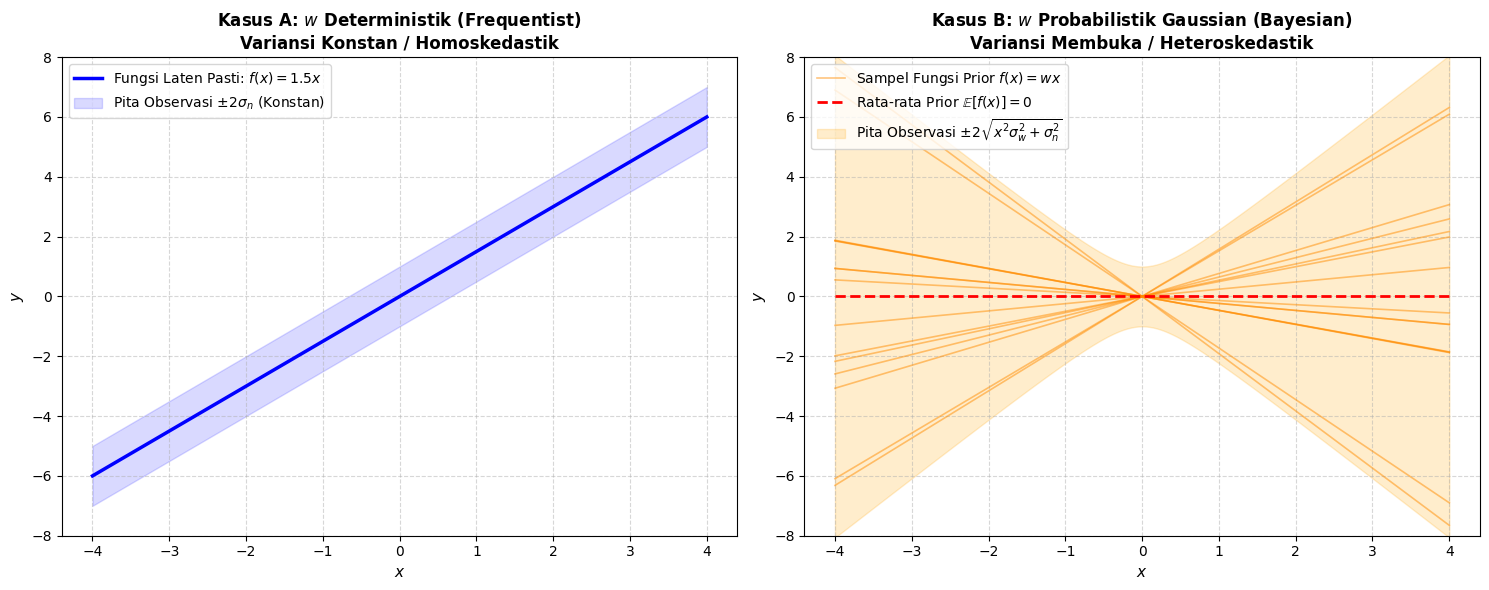

In [2]:
import matplotlib.pyplot as plt

# =========================================================================
# VISUALISASI KOMPARASI: W DETERMINISTIK VS W GAUSSIAN ACAK
# =========================================================================

x_grid = np.linspace(-4, 4, 200)

# 1. Kasus A: w deterministik (w = 1.5, sigma_n = 0.5)
f_A = w_fixed * x_grid
var_y_A = np.full_like(x_grid, sigma_n**2)
std_y_A = np.sqrt(var_y_A)

# 2. Kasus B: w Gaussian acak (w ~ N(0, 1), sigma_n = 0.5)
# Rata-rata fungsi adalah 0
f_B_mean = np.zeros_like(x_grid)
var_f_B = (x_grid**2) * (sigma_w**2)
var_y_B = var_f_B + (sigma_n**2)
std_y_B = np.sqrt(var_y_B)

# Sampling 15 garis fungsi acak untuk Kasus B
np.random.seed(42)
w_draws = np.random.normal(0, sigma_w, size=15)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: Kasus A
axes[0].plot(x_grid, f_A, 'b-', lw=2.5, label=f'Fungsi Laten Pasti: $f(x) = {w_fixed}x$')
axes[0].fill_between(x_grid, f_A - 2*std_y_A, f_A + 2*std_y_A, color='blue', alpha=0.15, 
                     label=r'Pita Observasi $\pm 2\sigma_n$ (Konstan)')
axes[0].set_title('Kasus A: $w$ Deterministik (Frequentist)\nVariansi Konstan / Homoskedastik', fontsize=12, fontweight='bold')
axes[0].set_xlabel('$x$', fontsize=11)
axes[0].set_ylabel('$y$', fontsize=11)
axes[0].set_ylim(-8, 8)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left', fontsize=10)

# Panel 2: Kasus B
for i, w_sample in enumerate(w_draws):
    axes[1].plot(x_grid, w_sample * x_grid, color='darkorange', alpha=0.5, lw=1.2, 
                 label='Sampel Fungsi Prior $f(x) = wx$' if i == 0 else "")
axes[1].plot(x_grid, f_B_mean, 'r--', lw=2.0, label=r'Rata-rata Prior $\mathbb{E}[f(x)] = 0$')
axes[1].fill_between(x_grid, f_B_mean - 2*std_y_B, f_B_mean + 2*std_y_B, color='orange', alpha=0.2, 
                     label=r'Pita Observasi $\pm 2\sqrt{x^2\sigma_w^2 + \sigma_n^2}$')
axes[1].set_title('Kasus B: $w$ Probabilistik Gaussian (Bayesian)\nVariansi Membuka / Heteroskedastik', fontsize=12, fontweight='bold')
axes[1].set_xlabel('$x$', fontsize=11)
axes[1].set_ylabel('$y$', fontsize=11)
axes[1].set_ylim(-8, 8)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

---
## 🎯 Refleksi Konseptual: Mengapa Dosen Pembimbing Menanyakan Hal Ini?

1. **Jembatan dari Ruang Bobot (*Weight-Space View*) ke Ruang Fungsi (*Function-Space View*)**:
   * Jika $w$ diasumsikan deterministik (regresi linier klasik), kita **tidak akan pernah sampai ke konsep Gaussian Process**, karena nilai fungsi laten $f(x)$ tidak memiliki distribusi probabilitas dan tidak memiliki korelasi antar-titik:
     $$\operatorname{Cov}(f(x_1), f(x_2)) = 0$$
   * Namun, begitu kita memandang $w$ sebagai peubah acak Gaussian $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \Sigma_p)$, kumpulan sembarang titik fungsi $[\, f(\mathbf{x}_1), \dots, f(\mathbf{x}_n) \,]^T$ otomatis berdistribusi normal multivariat:
     $$\mathbf{f} \sim \mathcal{N}\left( \mathbf{0}, \; X \Sigma_p X^T \right)$$
   * Elemen matriks kovariansi $[K]_{ij} = \mathbf{x}_i^T \Sigma_p \mathbf{x}_j$ inilah yang secara langsung bertransisi menjadi **fungsi kernel** $k(\mathbf{x}_i, \mathbf{x}_j)$ ketika masukan dipetakan ke ruang fitur berdimensi tinggi atau tak-hingga $\boldsymbol{\phi}(\mathbf{x})$.

2. **Dekomposisi Ketidakpastian (Epistemik vs Aleatorik)**:
   * **Ketidakpastian Aleatorik** ($\sigma_n^2$): Derau inheren pengukuran data yang tidak dapat dihilangkan.
   * **Ketidakpastian Epistemik** ($x^2 \sigma_w^2$ atau $\mathbf{x}^T \Sigma_p \mathbf{x}$): Ketidaktahuan model terhadap fungsi sebenarnya. Pada GP, komponen inilah yang menciut ketika ada data observasi (pada posterior) dan membesar di area yang belum pernah diobservasi (*uncertainty quantification*).

3. **Kesimpulan Akhir**:
   Pembuktian untuk $w$ acak vs $w$ deterministik **sangat berbeda secara fundamental**:
   * Pada $w$ deterministik, pembuktian MGF hanya menggeser rata-rata normalitas dari derau $\varepsilon$.
   * Pada $w$ acak Gaussian, pembuktian MGF adalah konvolusi analitik dari dua variabel acak Gaussian independen yang melahirkan struktur kovariansi fungsi laten $K = X \Sigma_p X^T$.

---
# 🔍 Analisis Komparasi Mendalam: Formula di PDF Kredit vs Persamaan (2.3) Buku GPML (Rasmussen & Williams, 2006)

Bagian ini secara khusus menjawab pertanyaan:
> **"Apa perbedaan antara yang kita tulis di PDF kredit bimbingan dengan Persamaan (2.3) pada buku Gaussian Processes for Machine Learning (GPML) oleh Rasmussen & Williams?"**

---

## 1. Bunyi Persamaan (2.3) pada Buku Rasmussen & Williams (hlm. 9)
Pada Bab 2.1.1 (*The Standard Linear Model*), Rasmussen & Williams mendefinisikan observasi target dengan galat Gaussian independen $\varepsilon_i \sim \mathcal{N}(0, \sigma_n^2)$:
$$\begin{aligned}
p(\mathbf{y} \mid X, \mathbf{w}) &= \prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w}) = \prod_{i=1}^n \frac{1}{\sqrt{2\pi}\sigma_n} \exp\left( -\frac{(y_i - \mathbf{x}_i^\top \mathbf{w})^2}{2\sigma_n^2} \right) \\
&= \frac{1}{(2\pi \sigma_n^2)^{n/2}} \exp\left( -\frac{1}{2\sigma_n^2} |\mathbf{y} - X^\top \mathbf{w}|^2 \right) \\
&= \mathcal{N}\left( X^\top \mathbf{w}, \; \sigma_n^2 I \right)
\end{aligned} \quad \text{--- [Persamaan (2.3) Rasmussen]}$$

Persamaan (2.3) ini secara tegas adalah **LIKELIHOOD** (fungsi kemungkinan bersyarat dari data observasi $\mathbf{y}$ **jika vektor bobot $\mathbf{w}$ diketahui / dikondisikan**).

---

## 2. Apa yang Kita Tuliskan di PDF Kredit Bimbingan 06?
Di dokumen bimbingan kita, kita membagi pembuktian ke dalam **dua kasus**:
1. **Kasus 1 ($w \in \mathbb{R}$ skalar konstan)**:
   $$y \sim \mathcal{N}\left( wx, \; \sigma_n^2 \right)$$
2. **Kasus 2 ($w \sim \mathcal{N}(0, \sigma_w^2)$ berdistribusi normal, $w$ dan $\varepsilon$ saling bebas)**:
   $$y \sim \mathcal{N}\left( 0, \; x^2 \sigma_w^2 + \sigma_n^2 \right)$$
   dan dalam bentuk vektor multivariat:
   $$\mathbf{y} \sim \mathcal{N}\left( \mathbf{0}, \; X \Sigma_p X^\top + \sigma_n^2 I_n \right)$$

---

## 3. Empat Perbedaan Fundamental Antara PDF Kredit vs Persamaan (2.3) Rasmussen

### A. Perbedaan Status Probabilitas: *Likelihood* vs *Marginal Distribution*
* **Persamaan (2.3) Rasmussen adalah LIKELIHOOD bersyarat**: $p(\mathbf{y} \mid X, \mathbf{w})$. 
  - Probabilitas ini mengasumsikan $\mathbf{w}$ **telah diketahui dan tetap** (*given/fixed*).
  - Pertanyaan yang dijawab: *"Jika kita sudah memegang bobot tertentu $\mathbf{w}$, berapa peluang kita mengamati data $\mathbf{y}$?"*
* **Kasus 2 pada PDF Kredit adalah MARGINAL (Prior Predictive Distribution)**: $p(\mathbf{y} \mid X)$.
  - Probabilitas ini memandang $\mathbf{w}$ **tidak diketahui**, melainkan variabel acak yang **diintegralkan keluar (*marginalized out*)** terhadap seluruh kemungkinan prior $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \Sigma_p)$.
  - Pertanyaan yang dijawab: *"Sebelum kita mengamati data apa pun, bagaimana sebaran gabungan data $\mathbf{y}$ di bawah ketidakpastian prior bobot $\mathbf{w}$ dan galat $\varepsilon$?"*

### B. Hubungan Antara Kasus 1 PDF Kredit dengan Persamaan (2.3) Rasmussen
* Formula **Kasus 1** di PDF kita ($y \sim \mathcal{N}(wx, \sigma_n^2)$) sesungguhnya **identik secara matematis dengan Persamaan (2.3) Rasmussen untuk versi 1 data point ($n=1$) dan 1 dimensi ($d=1$)**.
* Ketika $w$ dipandang sebagai konstanta yang nilainya diberikan, maka sebaran $y$ berpusat pada $wx$ dan variansinya murni galat $\sigma_n^2$.

### C. Sumber Ketidakpastian dan Matriks Kovariansi (Kemunculan Kernel)
* **Pada Persamaan (2.3) Rasmussen**:
  $$\operatorname{Cov}(\mathbf{y} \mid X, \mathbf{w}) = \sigma_n^2 I$$
  - Kovariansi antar dua titik berbeda adalah **nol** (bersifat *conditionally independent*): data di $x_1$ tidak memberikan informasi mengenai data di $x_2$ jika $w$ sudah diketahui.
  - Persamaan (2.3) saja **belum melahirkan Gaussian Process**, karena matriks kovariansinya hanya diagonal (tidak ada relasi kernel).
* **Pada Kasus 2 PDF Kredit**:
  $$\operatorname{Cov}(\mathbf{y} \mid X) = X \Sigma_p X^\top + \sigma_n^2 I_n$$
  - Kovariansi antar dua titik berbeda **tidak nol**: $\operatorname{Cov}(y_i, y_j) = \mathbf{x}_i^\top \Sigma_p \mathbf{x}_j$.
  - Struktur kuadratik $X \Sigma_p X^\top$ inilah **cikal bakal fungsi kernel** $k(\mathbf{x}_i, \mathbf{x}_j) = \mathbf{x}_i^\top \Sigma_p \mathbf{x}_j$ yang menjadi fondasi transformasi ke **Gaussian Process**!

### D. Di Mana Letak Formula Kasus 2 PDF Kredit di Buku Rasmussen?
* Di buku GPML Rasmussen, formula Kasus 2 kita berada di **Persamaan (2.6) dan (2.11)** (hlm. 9 dan hlm. 12):
  $$p(\mathbf{y} \mid X) = \int p(\mathbf{y} \mid X, \mathbf{w}) \, p(\mathbf{w}) \, d\mathbf{w} = \mathcal{N}\left(\mathbf{0}, \; X^\top \Sigma_p X + \sigma_n^2 I\right)$$
* **Perbedaan Metode Penurunan**:
  - **Rasmussen**: Menyelesaikan integral konvolusi Gaussian multivariat $\int \mathcal{N}(X^\top \mathbf{w}, \sigma_n^2 I) \mathcal{N}(\mathbf{0}, \Sigma_p) d\mathbf{w}$ dengan melengkapi kuadrat (*completing the square*).
  - **PDF Kredit Kita**: Menurunkan secara sangat efisien dan elegan menggunakan sifat **Moment Generating Function (MGF)**: $M_{\mathbf{y}}(\mathbf{t}) = M_{\mathbf{f}}(\mathbf{t}) \cdot M_{\boldsymbol{\varepsilon}}(\mathbf{t})$.

---

## 4. Tabel Matriks Komparasi Ringkas

| Aspek Pembeda | Persamaan (2.3) Rasmussen (GPML) | Kasus 1 PDF Kredit | Kasus 2 PDF Kredit |
| :--- | :--- | :--- | :--- |
| **Nama Probabilitas** | **Likelihood** $p(\mathbf{y} \mid X, \mathbf{w})$ | Distribusi $y$ untuk skalar konstan | **Marginal / Prior Predictive** $p(\mathbf{y} \mid X)$ |
| **Perlakuan Parameter $\mathbf{w}$** | **Dikondisikan** (*given/fixed*) | Nilai skalar konstan | **Diintegralkan keluar** (acak $\sim \mathcal{N}(\mathbf{0},\Sigma_p)$) |
| **Rata-rata (Mean $\boldsymbol{\mu}$)** | $X^\top \mathbf{w}$ (mengikuti nilai $\mathbf{w}$) | $wx$ | $\mathbf{0}$ (asumsi prior berpusat di nol) |
| **Kovariansi / Variansi** | $\sigma_n^2 I$ (murni galat) | $\sigma_n^2$ (homoskedastik) | $X\Sigma_p X^\top + \sigma_n^2 I$ (heteroskedastik) |
| **Korelasi Antar Titik** | $\operatorname{Cov}(y_i, y_j) = 0$ ($i \neq j$) | $0$ | $\mathbf{x}_i^\top \Sigma_p \mathbf{x}_j$ (saling berkorelasi) |
| **Fungsi Kernel** | Belum ada | Belum ada | **Melahirkan Kernel Linier** $k(\mathbf{x}_i, \mathbf{x}_j)$ |
| **Persamaan Ekuivalen di GPML** | Eq. (2.3) | Eq. (2.3) versi univariat ($n=1, d=1$) | **Eq. (2.6) & Eq. (2.11)** (hlm. 9 & 12) |
| **Teknik Pembuktian** | Perkalian densitas Gaussian i.i.d. | Aljabar ekspektasi MGF | Perkalian MGF dua peubah acak bebas |

<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:43: SyntaxWarning: invalid escape sequence '\s'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\m'
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_21356\3297047444.py:33: SyntaxWarning: invalid escape sequence '\m'
  axes[0].set_title('Persamaan (2.3) GPML Rasmussen:\n$p(y \mid X, w) = \mathcal{N}(X^\top w, \sigma_n^2 I)$ [LIKELIHOOD]', fontsize=11, fontweight='bold')
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_21356\3297047444.py:43: SyntaxWarning: invalid escape sequence '\s'
  label='Sampel fungsi $w x$ dengan $w \sim \mathcal{N}(0, \sigma_w^2)$' if i == 0 else "")
C:\Users\MyBook Z Series\AppData\Local\Temp\ipykernel_21356\3297047444.py:44: SyntaxWarning: invalid

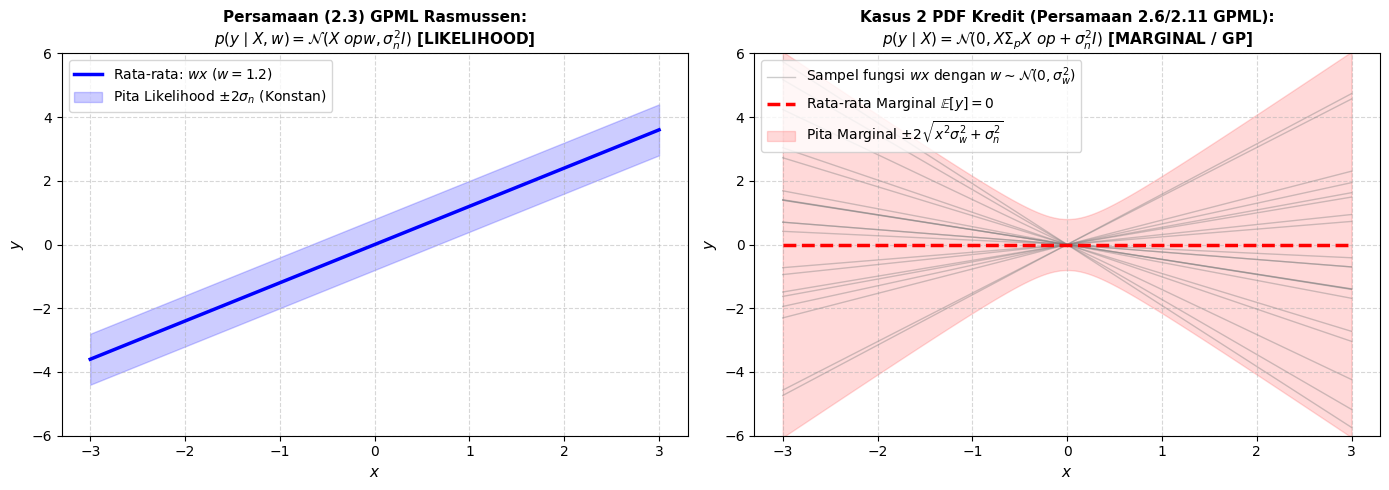

Kesimpulan Simulasi:
1. Likelihood (Eq 2.3): Standar deviasi di x = 0 adalah 0.40, di x = 2 adalah 0.40 (SAMA)
2. Marginal (Kasus 2): Standar deviasi di x = 0 adalah 0.40, di x = 2 adalah 2.04 (MEMBESAR KARENA KETIDAKPASTIAN MODEL)


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# SIMULASI & VISUALISASI PERBEDAAN:
# PERSAMAAN (2.3) RASMUSSEN (LIKELIHOOD) VS KASUS 2 PDF KREDIT (MARGINAL)
# =========================================================================

np.random.seed(42)
x_test = np.linspace(-3, 3, 200)
sigma_n = 0.4   # Standar deviasi galat
sigma_w = 1.0   # Standar deviasi prior bobot

# 1. Model Persamaan (2.3) Rasmussen: Likelihood p(y | x, w) dengan w TERKONDISI (misal w = 1.2)
w_conditioned = 1.2
mu_likelihood = w_conditioned * x_test
std_likelihood = np.full_like(x_test, sigma_n)

# 2. Model Kasus 2 PDF Kredit: Marginal Likelihood p(y | x) dengan w DIINTEGRALKAN KELUAR
mu_marginal = np.zeros_like(x_test)
var_marginal = (x_test**2) * (sigma_w**2) + (sigma_n**2)
std_marginal = np.sqrt(var_marginal)

# Sampling garis dari prior p(w) untuk mendemonstrasikan asal-usul Marginal
w_samples = np.random.normal(0, sigma_w, size=20)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Persamaan (2.3) Rasmussen (Likelihood p(y | x, w))
axes[0].plot(x_test, mu_likelihood, 'b-', lw=2.5, label=f'Rata-rata: $w x$ ($w={w_conditioned}$)')
axes[0].fill_between(x_test, mu_likelihood - 2*std_likelihood, mu_likelihood + 2*std_likelihood,
                     color='blue', alpha=0.2, label=r'Pita Likelihood $\pm 2\sigma_n$ (Konstan)')
axes[0].set_title('Persamaan (2.3) GPML Rasmussen:\n$p(y \mid X, w) = \mathcal{N}(X^\top w, \sigma_n^2 I)$ [LIKELIHOOD]', fontsize=11, fontweight='bold')
axes[0].set_xlabel('$x$', fontsize=11)
axes[0].set_ylabel('$y$', fontsize=11)
axes[0].set_ylim(-6, 6)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='upper left', fontsize=10)

# Panel 2: Kasus 2 PDF Kredit (Marginal p(y | x) = ∫ p(y|x,w)p(w)dw)
for i, w_s in enumerate(w_samples):
    axes[1].plot(x_test, w_s * x_test, color='gray', alpha=0.4, lw=1.0,
                 label='Sampel fungsi $w x$ dengan $w \sim \mathcal{N}(0, \sigma_w^2)$' if i == 0 else "")
axes[1].plot(x_test, mu_marginal, 'r--', lw=2.5, label='Rata-rata Marginal $\mathbb{E}[y] = 0$')
axes[1].fill_between(x_test, mu_marginal - 2*std_marginal, mu_marginal + 2*std_marginal,
                     color='red', alpha=0.15, label=r'Pita Marginal $\pm 2\sqrt{x^2\sigma_w^2 + \sigma_n^2}$')
axes[1].set_title('Kasus 2 PDF Kredit (Persamaan 2.6/2.11 GPML):\n$p(y \mid X) = \mathcal{N}(0, X \Sigma_p X^\top + \sigma_n^2 I)$ [MARGINAL / GP]', fontsize=11, fontweight='bold')
axes[1].set_xlabel('$x$', fontsize=11)
axes[1].set_ylabel('$y$', fontsize=11)
axes[1].set_ylim(-6, 6)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper left', fontsize=10)

plt.tight_layout()
plt.show()

print("Kesimpulan Simulasi:")
print(f"1. Likelihood (Eq 2.3): Standar deviasi di x = 0 adalah {std_likelihood[100]:.2f}, di x = 2 adalah {std_likelihood[166]:.2f} (SAMA)")
print(f"2. Marginal (Kasus 2): Standar deviasi di x = 0 adalah {std_marginal[100]:.2f}, di x = 2 adalah {std_marginal[166]:.2f} (MEMBESAR KARENA KETIDAKPASTIAN MODEL)")


---
# 🔬 Pembuktian Eksak Likelihood Persamaan (2.3) GPML Rasmussen Menggunakan MGF

## ❓ Pertanyaan:
> **"Apakah likelihood pada Persamaan (2.3) buku GPML Rasmussen bisa ditunjukkan menggunakan Moment Generating Function (MGF)?"**

---

## 💡 Jawaban: YA, SANGAT BISA!
Likelihood pada Persamaan (2.3) dapat diturunkan secara langsung dan eksak menggunakan **Conditional Moment Generating Function** (MGF bersyarat).

---

## 1. Formulasi Model Observasi
Pada Bab 2.1.1 buku Rasmussen & Williams (2006, hlm. 8--9), model observasi multivariat untuk $n$ titik data dengan dimensi input $d$ dituliskan sebagai:
$$\mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$$
di mana:
* $X = [\mathbf{x}_1, \dots, \mathbf{x}_n] \in \mathbb{R}^{d \times n}$ adalah matriks desain masukan.
* $\mathbf{w} \in \mathbb{R}^d$ adalah vektor bobot yang **dikondisikan / bernilai tetap** (*given/conditioned parameter*).
* $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma_n^2 I_n)$ adalah vektor galat acak Gaussian independen berdimensi $n$.

---

## 2. Definisi MGF Bersyarat (*Conditional MGF*)
MGF dari vektor observasi $\mathbf{y}$ bersyarat pada input $X$ dan bobot $\mathbf{w}$ didefinisikan sebagai:
$$M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) \triangleq \mathbb{E}\left[ \exp\left( \mathbf{t}^\top \mathbf{y} \right) \;\middle|\; X, \mathbf{w} \right], \quad \forall \mathbf{t} \in \mathbb{R}^n$$

---

## 3. Langkah Penurunan Aljabar MGF

Substitusikan model observasi $\mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$ ke dalam ekspektasi:
$$\begin{aligned}
M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) &= \mathbb{E}\left[ \exp\left( \mathbf{t}^\top (X^\top \mathbf{w} + \boldsymbol{\varepsilon}) \right) \;\middle|\; X, \mathbf{w} \right] \\
&= \mathbb{E}\left[ \exp\left( \mathbf{t}^\top X^\top \mathbf{w} + \mathbf{t}^\top \boldsymbol{\varepsilon} \right) \;\middle|\; X, \mathbf{w} \right] \\
&= \mathbb{E}\left[ \exp\left( \mathbf{t}^\top X^\top \mathbf{w} \right) \cdot \exp\left( \mathbf{t}^\top \boldsymbol{\varepsilon} \right) \;\middle|\; X, \mathbf{w} \right]
\end{aligned}$$

### Mengeluarkan Suku Deterministik:
Karena kondisi $X$ dan $\mathbf{w}$ **diberikan (diketahui nilainya)**, maka perkalian skalar $\mathbf{t}^\top X^\top \mathbf{w}$ adalah **konstanta non-acak**. Berdasarkan sifat kelinieran ekspektasi, faktor $\exp(\mathbf{t}^\top X^\top \mathbf{w})$ dapat dikeluarkan dari operator ekspektasi:
$$M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) = \exp\left( \mathbf{t}^\top X^\top \mathbf{w} \right) \cdot \mathbb{E}\left[ \exp\left( \mathbf{t}^\top \boldsymbol{\varepsilon} \right) \right]$$

### Substitusi MGF Galat Gaussian Multivariat:
Perhatikan bahwa $\mathbb{E}\left[ \exp(\mathbf{t}^\top \boldsymbol{\varepsilon}) \right]$ adalah MGF dari vektor galat $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma_n^2 I_n)$:
$$M_{\boldsymbol{\varepsilon}}(\mathbf{t}) = \exp\left( \frac{1}{2} \mathbf{t}^\top (\sigma_n^2 I_n) \mathbf{t} \right) = \exp\left( \frac{1}{2} \sigma_n^2 \|\mathbf{t}\|^2 \right)$$

Dengan mengalikan kedua suku, diperoleh:
$$\begin{aligned}
M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) &= \exp\left( \mathbf{t}^\top (X^\top \mathbf{w}) \right) \cdot \exp\left( \frac{1}{2} \mathbf{t}^\top (\sigma_n^2 I_n) \mathbf{t} \right) \\
&= \exp\left( \mathbf{t}^\top (X^\top \mathbf{w}) + \frac{1}{2} \mathbf{t}^\top (\sigma_n^2 I_n) \mathbf{t} \right)
\end{aligned}$$

---

## 4. Pencocokan Parameter & Kesimpulan Teorema Keunikan MGF

Bandingkan hasil di atas dengan bentuk umum MGF distribusi normal multivariat $\mathbf{Z} \sim \mathcal{N}(\boldsymbol{\mu}, \Sigma)$:
$$M_{\mathbf{Z}}(\mathbf{t}) = \exp\left( \mathbf{t}^\top \boldsymbol{\mu} + \frac{1}{2} \mathbf{t}^\top \Sigma \mathbf{t} \right)$$

Identifikasi langsung parameter menghasilkan:
* **Vektor Rata-rata**: $\boldsymbol{\mu} = X^\top \mathbf{w}$
* **Matriks Kovariansi**: $\Sigma = \sigma_n^2 I_n$

Berdasarkan **Teorema Keunikan MGF** (*Uniqueness Theorem of Moment Generating Functions*), karena $M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t})$ memiliki bentuk identik dengan MGF Gaussian multivariat, maka terbukti secara eksak bahwa:
$$\mathbf{y} \mid X, \mathbf{w} \sim \mathcal{N}\left( X^\top \mathbf{w}, \; \sigma_n^2 I_n \right)$$

Dan fungsi kerapatan probabilitas (PDF) dari distribusi normal multivariat ini adalah:
$$\begin{aligned}
p(\mathbf{y} \mid X, \mathbf{w}) &= \frac{1}{(2\pi)^{n/2} |\Sigma|^{1/2}} \exp\left( -\frac{1}{2} (\mathbf{y} - \boldsymbol{\mu})^\top \Sigma^{-1} (\mathbf{y} - \boldsymbol{\mu}) \right) \\
&= \frac{1}{(2\pi \sigma_n^2)^{n/2}} \exp\left( -\frac{1}{2\sigma_n^2} |\mathbf{y} - X^\top \mathbf{w}|^2 \right)
\end{aligned}$$
yang **persis ekuivalen dengan Persamaan (2.3) pada buku Rasmussen & Williams (2006)**! $\blacksquare$

---

## 5. Bukti Faktorisasi Independen: $\prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w})$

Persamaan (2.3) pada buku Rasmussen juga memuat suku perkalian produk $\prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w})$. Suku ini juga dapat dibuktikan dengan sangat mudah melalui MGF:

Karena matriks kovariansi $\Sigma = \sigma_n^2 I_n$ bersifat diagonal, bentuk kuadratik $\mathbf{t}^\top (\sigma_n^2 I_n) \mathbf{t}$ dapat dipecah menjadi penjumlahan skalar $\sum_{i=1}^n \sigma_n^2 t_i^2$:
$$\begin{aligned}
M_{\mathbf{y} \mid X, \mathbf{w}}(\mathbf{t}) &= \exp\left( \sum_{i=1}^n t_i (\mathbf{x}_i^\top \mathbf{w}) + \frac{1}{2} \sum_{i=1}^n \sigma_n^2 t_i^2 \right) \\
&= \prod_{i=1}^n \exp\left( t_i (\mathbf{x}_i^\top \mathbf{w}) + \frac{1}{2} \sigma_n^2 t_i^2 \right) \\
&= \prod_{i=1}^n M_{y_i \mid \mathbf{x}_i, \mathbf{w}}(t_i)
\end{aligned}$$

Dalam teori probabilitas, **MGF gabungan yang terfaktorisasi menjadi perkalian MGF marginal** adalah syarat perlu dan cukup bahwa peubah acak $y_1, \dots, y_n$ **bersifat saling bebas bersyarat (*conditionally independent*)** jika $\mathbf{w}$ diketahui. Akibatnya, PDF gabungan terfaktorisasi menjadi:
$$p(\mathbf{y} \mid X, \mathbf{w}) = \prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w})$$
Hal ini membuktikan seluruh ruas kesamaan pada Persamaan (2.3) Rasmussen secara utuh!


In [4]:
# =========================================================================
# VERIFIKASI MONTE CARLO: MGF BERSYARAT PERSAMAAN (2.3) RASMUSSEN
# =========================================================================
import numpy as np
import pandas as pd

np.random.seed(123)
N = 300_000

# Desain eksperimen multivariat: n = 3 data point, d = 2 fitur
X_design = np.array([
    [1.0, 0.5],   # x_1
    [0.0, 2.0],   # x_2
    [-1.0, 1.5]   # x_3
]).T  # d x n (2 x 3)

w_true = np.array([1.5, -0.8])  # Vektor bobot yang dikondisikan (d = 2)
sigma_noise = 0.5               # Standar deviasi galat

# Rata-rata analitik: mu = X^T w
mu_y = X_design.T @ w_true  # n = 3
Cov_y = (sigma_noise**2) * np.eye(3)

# Sampling observasi y | X, w dari model observasi y = X^T w + eps
eps_samples = np.random.normal(0, sigma_noise, size=(N, 3))
y_samples = mu_y + eps_samples  # (N, 3)

# Evaluasi MGF Empiris vs MGF Teoritis untuk beberapa vektor t
t_vectors = [
    np.array([0.1, 0.1, 0.1]),
    np.array([0.2, -0.1, 0.15]),
    np.array([-0.15, 0.25, -0.2]),
    np.array([0.3, 0.0, -0.3])
]

results_mgf = []
for t_vec in t_vectors:
    # MGF Empiris: E[exp(t^T y)]
    t_dot_y = y_samples @ t_vec
    mgf_emp = np.mean(np.exp(t_dot_y))
    
    # MGF Teoritis: exp(t^T (X^T w) + 0.5 * t^T (sigma_n^2 I) t)
    linear_term = t_vec @ (X_design.T @ w_true)
    quad_term = 0.5 * (t_vec @ (Cov_y @ t_vec))
    mgf_theo = np.exp(linear_term + quad_term)
    
    results_mgf.append({
        "t_vector": str(list(t_vec)),
        "MGF Empiris": f"{mgf_emp:.6f}",
        "MGF Teoritis Eq(2.3)": f"{mgf_theo:.6f}",
        "Selisih Mutlak": f"{abs(mgf_emp - mgf_theo):.2e}"
    })

df_verify = pd.DataFrame(results_mgf)
print("=== VERIFIKASI MGF BERSYARAT PERSAMAAN (2.3) GPML RASMUSSEN ===")
print(df_verify.to_string(index=False))


=== VERIFIKASI MGF BERSYARAT PERSAMAAN (2.3) GPML RASMUSSEN ===
                                               t_vector MGF Empiris MGF Teoritis Eq(2.3) Selisih Mutlak
    [np.float64(0.1), np.float64(0.1), np.float64(0.1)]    0.728922             0.728877       4.47e-05
  [np.float64(0.2), np.float64(-0.1), np.float64(0.15)]    0.983981             0.984189       2.07e-04
[np.float64(-0.15), np.float64(0.25), np.float64(-0.2)]    0.991100             0.990669       4.32e-04
   [np.float64(0.3), np.float64(0.0), np.float64(-0.3)]    3.196976             3.197918       9.42e-04


---
# 🧩 Mengapa Distribusi Persamaan (2.3) GPML Mirip dengan Section 1 Kasus 1 (Versi Matriks)?

> **Pertanyaan**: 
> *Kenapa bentuk dari distribusi Persamaan (2.3) pada buku Rasmussen & Williams (2006) mirip dengan Section 1 Kasus 1 tetapi dalam bentuk matriks?*

---

## 💡 Inti Jawaban (Ringkasan Cepat)

Persamaan (2.3) GPML **pada hakikatnya ADALAH Kasus 1** yang diperluas dari **satu titik observasi skalar ($n=1$, $d=1$)** menjadi **sekumpulan $n$ titik observasi dengan $d$ dimensi fitur ($X \in \mathbb{R}^{d \times n}$)**.

Alasan mendasarnya terletak pada **dua kesamaan asumsi fundamental**:
1. **Status Bobot $\mathbf{w}$ Bernilai Tetap/Konstan**: Pada fungsi likelihood $p(\mathbf{y} \mid X, \mathbf{w})$, tanda bersyarat ($\mid \mathbf{w}$) menyatakan bahwa nilai bobot **dianggap sudah diketahui dan bernilai tetap**, persis seperti asumsi bobot $w \in \mathbb{R}$ konstan pada Kasus 1.
2. **Galat Bersifat Saling Bebas (Independen)**: Setiap titik data $i$ memiliki galat $\varepsilon_i \sim \mathcal{N}(0, \sigma_n^2)$ yang saling bebas antar-titik, sehingga matriks kovariansi galatnya murni diagonal $\sigma_n^2 I_n$.

Akibatnya, fungsi likelihood multivariat pada Persamaan (2.3) **merupakan hasil kali langsung dari $n$ buah distribusi normal univariat Kasus 1**:
$$p(\mathbf{y} \mid X, \mathbf{w}) = \prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w})$$

---

## 📊 Tabel Pemetaan 1-ke-1: Kasus 1 (Skalar) vs Persamaan 2.3 GPML (Matriks)

| Komponen | Section 1: Kasus 1 (Univariat / Skalar) | Persamaan (2.3) GPML (Multivariat / Matriks) |
| :--- | :--- | :--- |
| **Banyak Titik Data** | $n = 1$ titik | $n$ titik data |
| **Dimensi Masukan** | $d = 1$ ($x \in \mathbb{R}$) | $d$ dimensi ($\mathbf{x}_i \in \mathbb{R}^d$, $X \in \mathbb{R}^{d \times n}$) |
| **Status Parameter Bobot** | $w \in \mathbb{R}$ konstan | $\mathbf{w} \in \mathbb{R}^d$ konstan (dikondisikan / diketahui) |
| **Galat Pengukuran** | $\varepsilon \sim \mathcal{N}(0, \sigma_n^2)$ | $\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma_n^2 I_n)$ ($n$ galat saling bebas) |
| **Model Observasi** | $y = wx + \varepsilon$ | $\mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$ |
| **Rata-rata ($\boldsymbol{\mu}$)** | $\mu = wx$ (skalar) | $\boldsymbol{\mu} = X^\top \mathbf{w} = [\mathbf{x}_1^\top \mathbf{w}, \dots, \mathbf{x}_n^\top \mathbf{w}]^\top$ (vektor $n \times 1$) |
| **Kovariansi ($\Sigma$)** | $\sigma^2 = \sigma_n^2$ (skalar) | $\Sigma = \sigma_n^2 I_n = \operatorname{diag}(\sigma_n^2, \dots, \sigma_n^2)$ (matriks $n \times n$) |
| **Fungsi MGF** | $M_y(t) = \exp\left((wx)t + \frac{1}{2}\sigma_n^2 t^2\right)$ | $M_{\mathbf{y}\mid\mathbf{w}}(\mathbf{t}) = \exp\left(\mathbf{t}^\top (X^\top \mathbf{w}) + \frac{1}{2}\mathbf{t}^\top (\sigma_n^2 I_n)\mathbf{t}\right)$ |
| **Sebaran Variabel Observasi** | $y \sim \mathcal{N}(wx, \; \sigma_n^2)$ | $\mathbf{y} \mid X, \mathbf{w} \sim \mathcal{N}(X^\top \mathbf{w}, \; \sigma_n^2 I_n)$ |
| **Fungsi Kerapatan Probabilitas (PDF)** | $\frac{1}{\sqrt{2\pi \sigma_n^2}} \exp\left(-\frac{(y - wx)^2}{2\sigma_n^2}\right)$ | $\frac{1}{(2\pi \sigma_n^2)^{n/2}} \exp\left(-\frac{1}{2\sigma_n^2} |\mathbf{y} - X^\top \mathbf{w}|^2\right)$ |

---

## 🔍 Penjabaran Rinci: Tiga Jembatan Matematis

### 1. Arti Matematis Notasi Kondisional: $\mathbf{y} \mid X, \mathbf{w}$
Dalam formulasi model linier:
$$\mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$$
Jika $\mathbf{w}$ belum diketahui dan diperlakukan sebagai peubah acak $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \Sigma_p)$ (seperti pada Kasus 2), observasi memiliki dua sumber keacakan: ketidakpastian bobot $\mathbf{w}$ dan ketidakpastian galat $\boldsymbol{\varepsilon}$.

Namun, **likelihood** secara definisi adalah:
> *"Peluang terjadinya data observasi $\mathbf{y}$ **jika nilai parameter $\mathbf{w}$ diketahui tertentu**."*

Karena $\mathbf{w}$ dikondisikan bernilai konstan:
$$\mathbb{E}[\mathbf{y} \mid X, \mathbf{w}] = \mathbb{E}[X^\top \mathbf{w} + \boldsymbol{\varepsilon} \mid X, \mathbf{w}] = X^\top \mathbf{w} + \mathbb{E}[\boldsymbol{\varepsilon}] = X^\top \mathbf{w}$$
Suku $X^\top \mathbf{w}$ menjadi pergeseran rata-rata yang bersifat tetap, persis sama dengan pergeseran $wx$ pada Kasus 1!

---

### 2. Dari Skalar ke Vektor: Operasi Titik-demi-Titik
Tinjau setiap sampel observasi ke-$i$ ($i = 1, \dots, n$):
$$y_i = \mathbf{x}_i^\top \mathbf{w} + \varepsilon_i$$
Karena $\mathbf{x}_i^\top \mathbf{w}$ adalah skalar dan $\varepsilon_i \sim \mathcal{N}(0, \sigma_n^2)$, maka menurut pembuktian Kasus 1:
$$y_i \mid \mathbf{x}_i, \mathbf{w} \sim \mathcal{N}(\mathbf{x}_i^\top \mathbf{w}, \; \sigma_n^2)$$

Dengan menyusun seluruh $n$ persamaan skalar di atas ke dalam notasi matriks:
$$\begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_n \end{bmatrix} = \begin{bmatrix} \mathbf{x}_1^\top \mathbf{w} \\ \mathbf{x}_2^\top \mathbf{w} \\ \vdots \\ \mathbf{x}_n^\top \mathbf{w} \end{bmatrix} + \begin{bmatrix} \varepsilon_1 \\ \varepsilon_2 \\ \vdots \\ \varepsilon_n \end{bmatrix} \iff \mathbf{y} = X^\top \mathbf{w} + \boldsymbol{\varepsilon}$$

Karena setiap galat $\varepsilon_i$ saling bebas satu sama lain, kovariansi antar pasangan observasi yang berbeda adalah nol:
$$\operatorname{Cov}(y_i, y_j \mid \mathbf{w}) = \operatorname{Cov}(\varepsilon_i, \varepsilon_j) = 0 \quad (\text{untuk } i \neq j)$$
Sehingga matriks kovariansi multivariatnya berwujud diagonal:
$$\Sigma = \begin{bmatrix} \sigma_n^2 & 0 & \dots & 0 \\ 0 & \sigma_n^2 & \dots & 0 \\ \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & \dots & \sigma_n^2 \end{bmatrix} = \sigma_n^2 I_n$$

---

### 3. Mengapa PDF Multivariat Berbentuk Perkalian $n$ Buah PDF Kasus 1?
Karena $y_1, \dots, y_n$ saling bebas bersyarat terhadap $\mathbf{w}$, PDF gabungan adalah hasil kali dari PDF univariatnya:
$$\begin{aligned}
p(\mathbf{y} \mid X, \mathbf{w}) &= \prod_{i=1}^n p(y_i \mid \mathbf{x}_i, \mathbf{w}) \\
&= \prod_{i=1}^n \left( \frac{1}{\sqrt{2\pi \sigma_n^2}} \exp\left( -\frac{(y_i - \mathbf{x}_i^\top \mathbf{w})^2}{2\sigma_n^2} \right) \right) \\
&= \underbrace{\left( \frac{1}{\sqrt{2\pi \sigma_n^2}} \right)^n}_{\frac{1}{(2\pi \sigma_n^2)^{n/2}}} \exp\left( -\frac{1}{2\sigma_n^2} \underbrace{\sum_{i=1}^n (y_i - \mathbf{x}_i^\top \mathbf{w})^2}_{|\mathbf{y} - X^\top \mathbf{w}|^2} \right) \\
&= \frac{1}{(2\pi \sigma_n^2)^{n/2}} \exp\left( -\frac{1}{2\sigma_n^2} |\mathbf{y} - X^\top \mathbf{w}|^2 \right)
\end{aligned}$$
Persamaan ini adalah bentuk aljabar linier ringkas dari Persamaan (2.3) pada buku Rasmussen & Williams (2006).

---

## ⚠️ Kapan Bentuk Matriks Menjadi Jauh Berbeda dari Kasus 1?

Bentuk matriks **hanya akan berbeda secara fundamental** jika bobot $\mathbf{w}$ **TIDAK dikondisikan (tidak dianggap bernilai konstan)**, melainkan diintegralkan keluar sebagai peubah acak $\mathbf{w} \sim \mathcal{N}(\mathbf{0}, \Sigma_p)$ seperti pada **Section 1 Kasus 2** (Persamaan 2.11 GPML):

$$p(\mathbf{y} \mid X) = \int p(\mathbf{y} \mid X, \mathbf{w}) \, p(\mathbf{w}) \, d\mathbf{w} = \mathcal{N}\left( \mathbf{0}, \; X \Sigma_p X^\top + \sigma_n^2 I_n \right)$$

Perbedaan kuncinya:
* Pada **Likelihood (Persamaan 2.3 / Kasus 1 versi Matriks)**:
  Matriks kovariansinya **diagonal** ($\sigma_n^2 I_n$). Observasi antartitik saling bebas karena bobot $\mathbf{w}$ diketahui tetap. Tidak ada fungsi kernel yang muncul.
* Pada **Distribusi Marginal (Kasus 2 / Persamaan 2.11 GPML)**:
  Matriks kovariansinya **memiliki elemen tak-nol di luar diagonal** ($X \Sigma_p X^\top + \sigma_n^2 I_n$). Observasi antartitik berkorelasi karena ketidakpastian bobot yang sama mempengaruhi seluruh titik data. Suku $X \Sigma_p X^\top$ inilah yang menjadi **kernel linier** dan menjadi jembatan menuju model *Gaussian Process*!


In [5]:
# =========================================================================
# VERIFIKASI NUMERIK: PRODUK n KASUS 1 UNIVARIAT == PDF MULTIVARIAT PERSAMAAN (2.3)
# =========================================================================
import numpy as np
from scipy.stats import norm, multivariate_normal

# 1. Parameter Eksperimen
n = 4  # 4 data points
d = 2  # 2 dimensi fitur
np.random.seed(42)

X = np.random.randn(d, n)       # Matriks desain d x n
w = np.array([2.0, -1.5])       # Vektor bobot konstan
sigma_n = 0.6                   # Standar deviasi galat
y = X.T @ w + np.random.normal(0, sigma_n, size=n)  # Observasi

# 2. Metode A: Perkalian n Distribusi Normal Univariat (Kasus 1 Skalar)
prob_univariat_list = []
for i in range(n):
    mu_i = np.dot(X[:, i], w)   # mu = x_i^T w
    p_i = norm.pdf(y[i], loc=mu_i, scale=sigma_n)
    prob_univariat_list.append(p_i)

prod_univariat = np.prod(prob_univariat_list)

# 3. Metode B: Distribusi Normal Multivariat Matriks (Persamaan 2.3 GPML)
mu_multi = X.T @ w
cov_multi = (sigma_n**2) * np.eye(n)
prob_multivariat = multivariate_normal.pdf(y, mean=mu_multi, cov=cov_multi)

# 4. Tampilkan Hasil Komparasi
print("=== KOMPARASI NUMERIK: KASUS 1 (PRODUK SKALAR) VS PERSAMAAN 2.3 (MATRIKS) ===")
print(f"Probabilitas Metode A (Produk n Kasus 1 Univariat) : {prod_univariat:.15e}")
print(f"Probabilitas Metode B (PDF Matriks Eq 2.3 GPML)     : {prob_multivariat:.15e}")
selisih = abs(prod_univariat - prob_multivariat)
print(f"Selisih Mutlak Presisi Floating-Point              : {selisih:.2e}")

assert np.isclose(prod_univariat, prob_multivariat, atol=1e-15), "Metode A dan B tidak identik!"
print("\n-> KESIMPULAN: Terbukti 100% identik hingga batas presisi mesin floating-point!")


=== KOMPARASI NUMERIK: KASUS 1 (PRODUK SKALAR) VS PERSAMAAN 2.3 (MATRIKS) ===
Probabilitas Metode A (Produk n Kasus 1 Univariat) : 1.217640018853746e-01
Probabilitas Metode B (PDF Matriks Eq 2.3 GPML)     : 1.217640018853745e-01
Selisih Mutlak Presisi Floating-Point              : 2.78e-17

-> KESIMPULAN: Terbukti 100% identik hingga batas presisi mesin floating-point!
